In [1]:
import numpy as np
import matplotlib.pyplot as plt
import iddefix
from scipy.constants import c as c_light

## Import data & visualize the data

In [ ]:
# Importing wake potential data
data_wake_potential = np.loadtxt(
    "transitionsnew_beta.txt", comments="#", delimiter="\t"
)

# Extracting data
data_wake_time = data_wake_potential[:, 0] * 1e-9  # [s]
data_wake_dipolar = data_wake_potential[:, 2]  # [V/pC/mm]

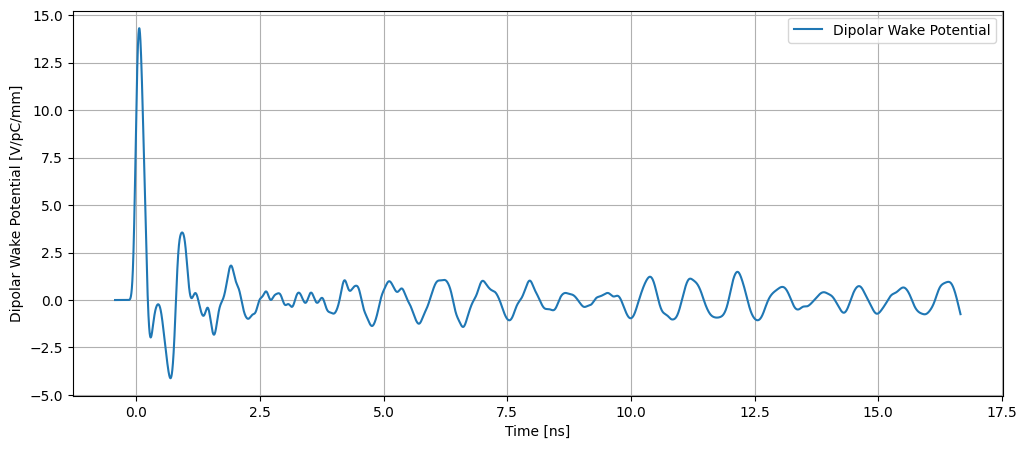

In [3]:
# Create subplots
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

# Plot data_wake_time vs data_wake_dipolar on the left
ax.plot(data_wake_time*1e9, data_wake_dipolar, label="Dipolar Wake Potential")
ax.set_xlabel("Time [ns]")
ax.set_ylabel("Dipolar Wake Potential [V/pC/mm]")
ax.grid(True)
ax.legend()

## Fitting of Wakepotential

Text(0.5, 0, 'frequency [GHz]')

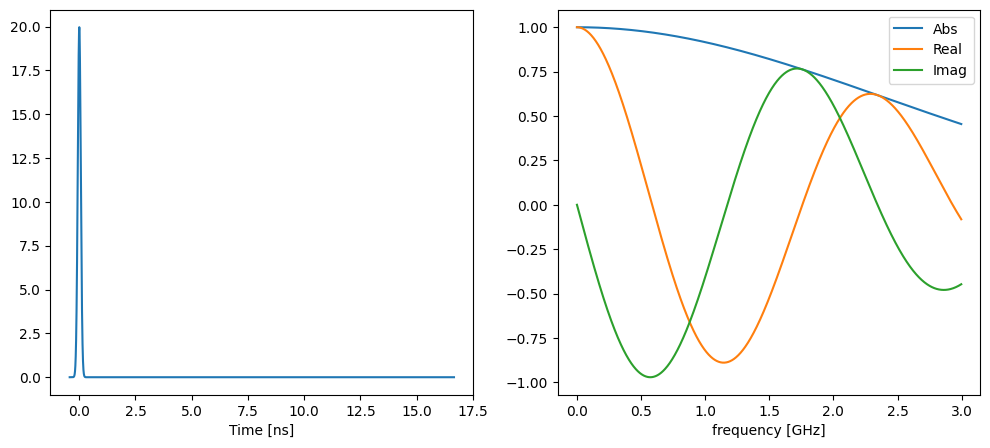

In [4]:
# Function that will be deconvolved under the hood!
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

sigma = 0.666666666666666e-10
data_time = data_wake_time
lambdas = (
    1
    / (sigma * np.sqrt(2 * np.pi))
    * np.exp(-(data_time**2) / (2 * sigma**2))
    / c_light
)

axs[0].plot(data_time * 1e9, lambdas, label="charge distribution")
axs[0].set_xlabel("Time [ns]")

ff, lambadf = iddefix.compute_fft(data_time, lambdas)
axs[1].plot(ff / 1e9, np.abs(lambadf), label="Abs")
axs[1].plot(ff / 1e9, np.real(lambadf), label="Real")
axs[1].plot(ff / 1e9, np.imag(lambadf), label="Imag")
axs[1].legend()
axs[1].set_xlabel("frequency [GHz]")

We can now use the deconvolution to observe the impedance and find the number of resonators. Notice how the impedance changes in the high frequency range due to the deconvolution:

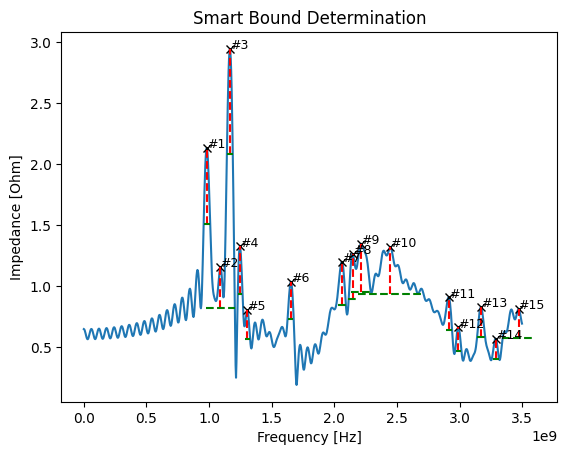

In [9]:
f, Z = iddefix.compute_deconvolution(
    data_wake_time, data_wake_dipolar, sigma=sigma, fmax=3.5e9
)

heights = np.zeros_like(Z)
heights[f < 1.0e9] = 1.2
heights[f>= 1.0e9] = 0.8
# heights[f >= 1.5e9] = 0.9
heights[f >= 2.0e9] = 1
heights[f >= 2.5e9] = 0.4
bounds = iddefix.SmartBoundDetermination(f, np.abs(Z), minimum_peak_height=heights, prominence=0.1)#, distance=30)
bounds.inspect()

In [10]:
f2, Z2 = iddefix.compute_fft(data_wake_time, data_wake_dipolar)

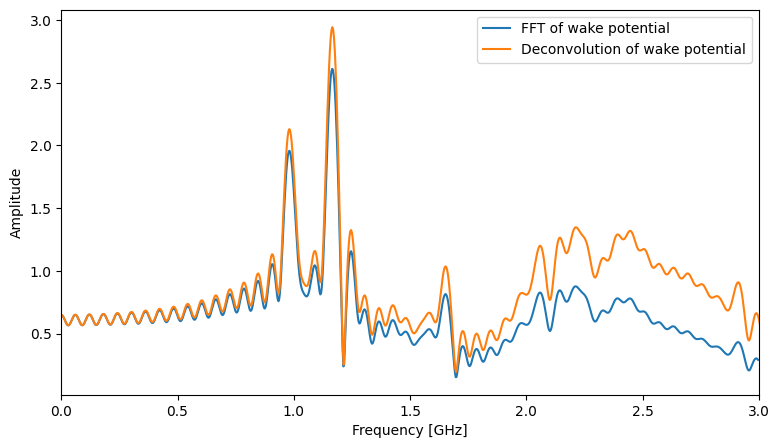

In [11]:
fig, ax = plt.subplots(1, 1, figsize=(9, 5))
ax.plot(f2*1e-9, np.abs(Z2), label="FFT of wake potential")
ax.plot(f*1e-9, np.abs(Z), label="Deconvolution of wake potential")
ax.set_xlim(0, 3.0)
ax.set_xlabel("Frequency [GHz]")
ax.set_ylabel("Amplitude")
ax.legend()
plt.show()

### Decimate the data to improve speed

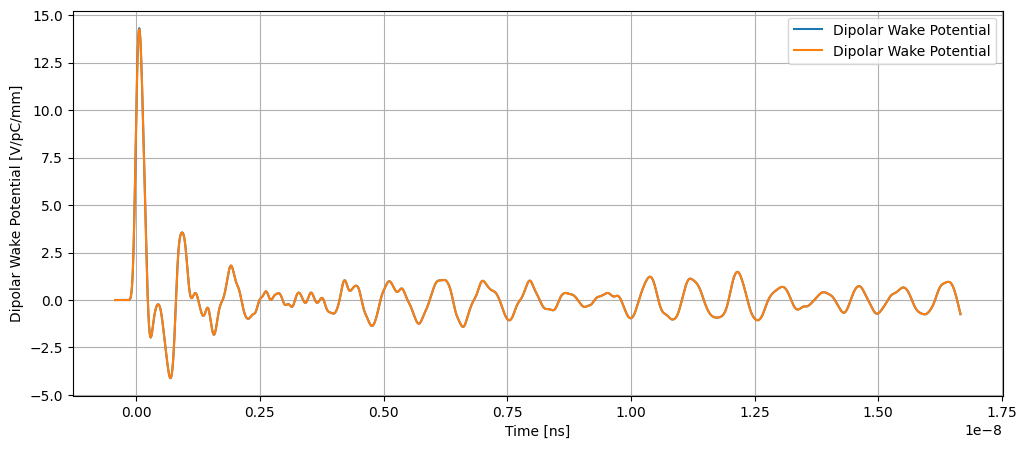

In [12]:
# Decimate wake data
x = np.linspace(data_wake_time[0], data_wake_time[-1], 1000)
y = np.interp(x, data_wake_time, data_wake_dipolar)

# Create subplots
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

# Plot data_wake_time vs data_wake_dipolar on the left
ax.plot(data_wake_time, data_wake_dipolar, label="Dipolar Wake Potential")
ax.plot(x, y, label="Dipolar Wake Potential")
ax.set_xlabel("Time [ns]")
ax.set_ylabel("Dipolar Wake Potential [V/pC/mm]")
ax.grid(True)
ax.legend()

data_wake_time = x
data_wake_dipolar = y

In [13]:
%%time
DE_model = iddefix.EvolutionaryAlgorithm(
    data_wake_time,
    data_wake_dipolar * c_light,  # remove normalization
    N_resonators=bounds.N_resonators,
    parameterBounds=bounds.parameterBounds,
    plane="transverse",
    fitFunction="wake potential",
    sigma=sigma,
    objectiveFunction=iddefix.ObjectiveFunctions.sumOfSquaredErrorReal,
)

DE_model.run_differential_evolution(
    maxiter=2000, popsize=180, tol=0.001, mutation=(0.1, 0.5), crossover_rate=0.8
)
print(DE_model.warning)

Differential Evolution:  27%|██▋       | 536/2000 [25:21<1:09:16,  2.84s/gen, conv=102.4 %]

[!] Warning: 14 parameter(s) have relative uncertainty >= 0.20 (max 4.20).


----------------------------------------------------------------------------
Resonator |   Rs [Ohm/m or Ohm]    |        Q         |       fres [Hz]        
----------------------------------------------------------------------------
    1     |   1.87e+00 ± 4.6e-01   |  89.09 ± 28.79   |   9.90e+08 ± 9.3e+05   
    2     |   9.27e-01 ± 5.7e-02   |   23.47 ± 2.53   |   1.08e+09 ± 1.4e+06   
    3     |   4.75e+00 ± 4.9e-01   |  89.40 ± 12.72   |   1.18e+09 ± 3.6e+05   
    4     |   1.06e+00 ± 1.6e-01   |  46.90 ± 19.44   |   1.25e+09 ± 1.7e+06   
    5     |   6.70e-01 ± 5.0e-02   |   15.57 ± 2.58   |   1.32e+09 ± 5.6e+06   
    6     |   8.30e-01 ± 4.3e-02   |   19.94 ± 1.59   |   1.65e+09 ± 2.2e+06   
    7     |   9.69e-01 ± 5.3e-01   | 162.51 ± 122.97  |   2.07e+09 ± 2.2e+06   
    8     |   1.02e+00 ± 6.0e-01   | 152.24 ± 131.72  |   2.16e+09 ± 2.6e+06   
    9     |   1.08e+00 ± 1.5e-01   |  71.26 ± 21.

In [14]:
DE_model.run_minimization_algorithm()

Method for minimization : Nelder-Mead
[!] Warning: 14 parameter(s) have relative uncertainty >= 0.20 (max 2.68).


----------------------------------------------------------------------------
Resonator |   Rs [Ohm/m or Ohm]    |        Q         |       fres [Hz]        
----------------------------------------------------------------------------
    1     |   1.99e+00 ± 6.3e-01   |  83.12 ± 44.00   |   1.00e+09 ± 1.6e+06   
    2     |   8.55e-01 ± 5.4e-02   |   25.81 ± 5.28   |   1.05e+09 ± 3.5e+06   
    3     |   5.11e+00 ± 2.9e-01   |   93.25 ± 7.17   |   1.18e+09 ± 2.4e+05   
    4     |   1.15e+00 ± 7.0e-02   |   42.22 ± 4.40   |   1.26e+09 ± 8.0e+05   
    5     |   6.34e-01 ± 2.7e-02   |   14.06 ± 1.00   |   1.41e+09 ± 2.2e+06   
    6     |   7.86e-01 ± 3.3e-02   |   21.71 ± 1.41   |   1.65e+09 ± 1.6e+06   
    7     |   9.62e-01 ± 3.0e-01   |  149.88 ± 63.82  |   2.07e+09 ± 1.5e+06   
    8     |   9.72e-01 ± 5.0e-01   | 151.58 ± 124.43  |   2.19e+09 ± 2.9e+06   
    9     |

### Showing the results:

With the parameters computed by `iddefix` evolutionary algorithm, we can generate analytcally the wake potential and compare it to the original data:

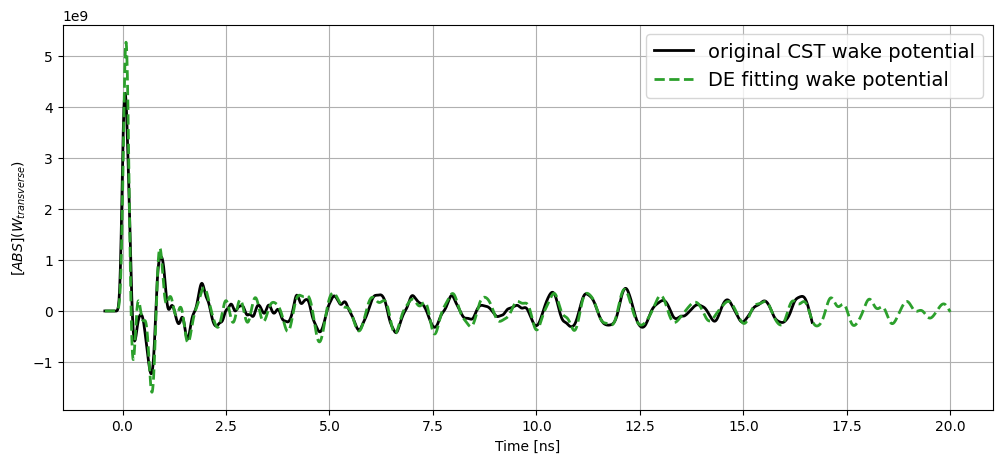

In [ ]:
time = np.linspace(data_wake_time[0], 20e-9, 10000)
fig, ax0 = plt.subplots(1, 1, figsize=(12, 5))

ax0.plot(
    DE_model.time_data * 1e9,
    DE_model.wake_potential_data,
    lw=2,
    c="k",
    label="original CST wake potential",
)

ax0.plot(
    time * 1e9,
    DE_model.get_wake_potential(time, sigma=sigma),
    lw=2,
    c="tab:green",
    linestyle="--",
    label="DE fitting wake potential",
)

ax0.set_xlabel("Time [ns]")
ax0.set_ylabel("$[ABS](W_{transverse})$")
ax0.legend(loc="best", fontsize=14)
ax0.grid()

## Impedance

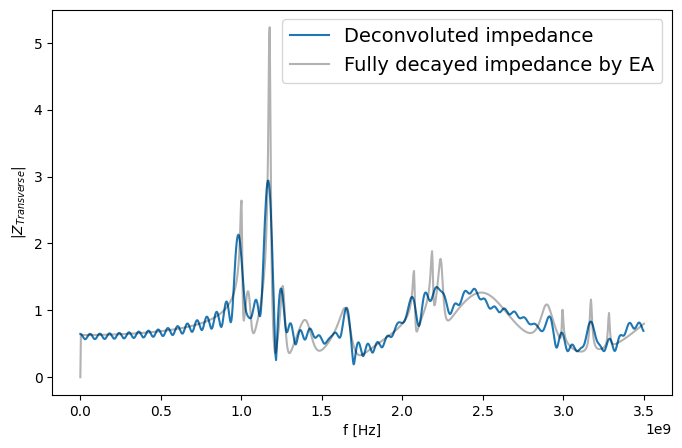

In [16]:
f, Z = iddefix.compute_deconvolution(
    data_wake_time, data_wake_dipolar, sigma=sigma, fmax=3.5e9
)
f_fd = np.linspace(0, 3.5e9, 1001)
Z_fd = DE_model.get_impedance(frequency_data=f_fd)

# Compare magnitude [ABS]
plt.figure(figsize=(8, 5))
plt.plot(f, np.abs(Z), c="tab:blue", label="Deconvoluted impedance")
plt.plot(f_fd , np.abs(Z_fd), color="k", alpha=0.3, label="Fully decayed impedance by EA")

plt.legend()
plt.xlabel("f [Hz]")
plt.ylabel("$|Z_{Transverse}|$")
plt.legend(loc="best", fontsize=14)

## Short bunch

We can also compute analytically the wake funciton from the parameters, and compare it to the wake potential. This differences are important for beam dynamic simulations, since the beam dynamic codes take as input the wake functions and not wake potentials!

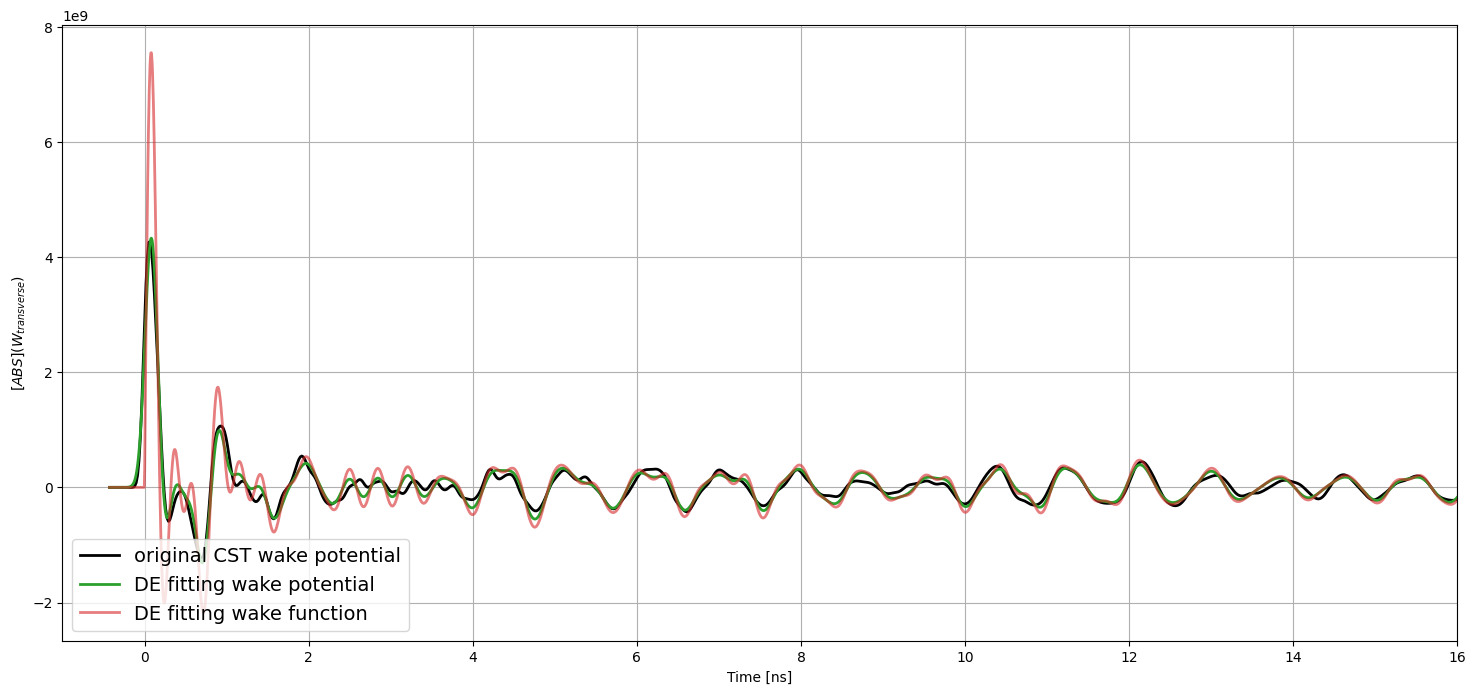

In [ ]:
time = np.linspace(data_wake_time[0], 50e-9, 10000)
fig, ax0 = plt.subplots(1, 1, figsize=(18, 8))
plottime = time *1e9

ax0.plot(
    data_wake_time * 1e9,
    data_wake_dipolar * c_light,
    lw=2,
    c="k",
    label="original CST wake potential",
)

ax0.plot(
    plottime,
    DE_model.get_wake_potential(time, sigma=sigma),
    lw=2,
    c="tab:green",
    linestyle="-",
    label="DE fitting wake potential",
)

ax0.plot(
    plottime,
    DE_model.get_wake(time),
    lw=2,
    c="tab:red",
    linestyle="-",
    label="DE fitting wake function",
    alpha=0.6,
)

ax0.set_xlabel("Time [ns]")
ax0.set_ylabel("$[ABS](W_{transverse})$")
ax0.legend(loc="lower left", fontsize=14)
ax0.set_xlim(-1, 16)
ax0.grid()

In [18]:
existing_data = np.loadtxt("transitionsnew_beta.txt", delimiter="\t", skiprows=1)

time_data = existing_data[:, 0]
dipolx = existing_data[:, 1]
quadx = existing_data[:, 3]
quady = existing_data[:, 4]

In [19]:
dipoly_wf = DE_model.get_wake(time) / c_light
dipoly_wp = DE_model.get_wake_potential(time, sigma=sigma) / c_light

In [ ]:
quady_wf = np.loadtxt("transitionsnew_beta_wf_q.txt", delimiter="\t", skiprows=1)[:, 4]
quady_wp = np.loadtxt("transitionsnew_beta_wp_q.txt", delimiter="\t", skiprows=1)[:, 4]

In [22]:
quady_wf = quady_wf
quady_wp = quady_wp

In [23]:
data_wf = np.column_stack((time_data, dipolx, dipoly_wf, quadx, quady_wf))
data_wp = np.column_stack((time_data, dipolx, dipoly_wp, quadx, quady_wp))

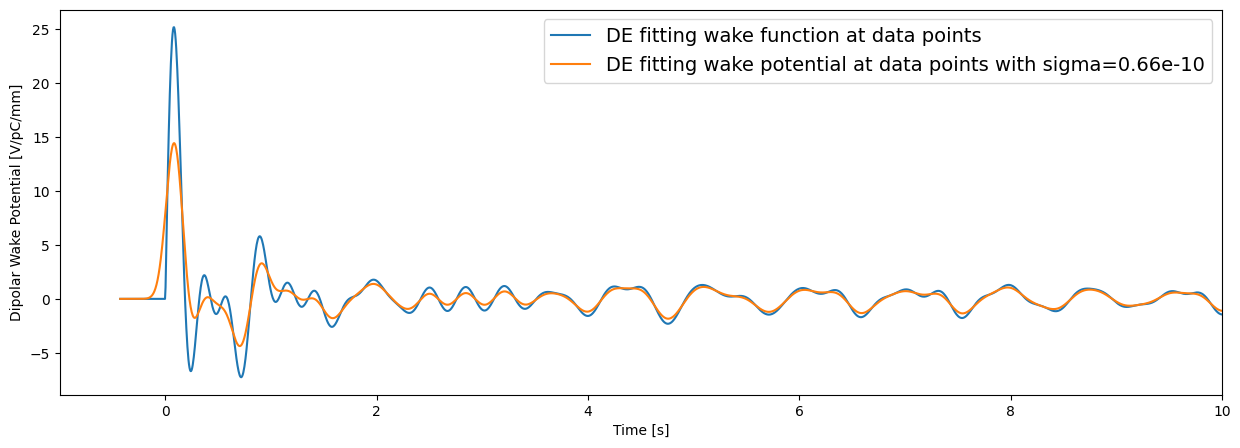

In [24]:
fig, ax = plt.subplots(figsize=(15, 5), sharex=True)
ax.plot(time_data, dipoly_wf, label="DE fitting wake function at data points")
ax.plot(time_data, dipoly_wp, label="DE fitting wake potential at data points with sigma=0.66e-10")
ax.set_xlabel("Time [s]")
ax.set_xlim(-1, 10)
ax.set_ylabel("Dipolar Wake Potential [V/pC/mm]")
ax.legend(loc="best", fontsize=14)
plt.show()

In [ ]:
np.savetxt("transitionsnew_beta_wf.txt", data_wf, delimiter="\t", header="time\tdipolx\tdipol_wf\tquadx\tquady_wf", comments="")
np.savetxt("transitionsnew_beta_wp.txt", data_wp, delimiter="\t", header="time\tdipolx\tdipol_wp\tquadx\tquady_wp", comments="")